<div dir="rtl">

# תרשימים להצגה

המחברת בונה גרסאות מעוצבות, בעזרת הספרייה `seaborn`, של תשעת התרשימים שבספר, ושומרת אותן בתיקייה `charts` שבמאגר. הן מיועדות להצגה ולשקפים. התרשימים שבספר עצמו נשארים אלה שבונה מחברת 03.

**אין כאן ניתוח חדש.** המחברת קוראת את אותם שלושה קבצים שבתיקייה `data/clean`, מריצה את אותו מבחן תמורות ואת אותה סימולציה עם אותו זרע אקראי, ובודקת שהערכים המרכזיים שמופיעים בתרשימים זהים למה שמחברת 03 מחשבת. אם יש הבדל, המחברת נעצרת לפני שהיא מציירת דבר. הכותרות נושאות את אותן הסתייגויות שבספר.

</div>

In [1]:
import textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.ft2font
import matplotlib.pyplot as plt
import matplotlib.ticker
import seaborn as sns

# Hebrew is laid out by matplotlib itself (libraqm, bundled since 3.11); raw strings, no python-bidi.
assert hasattr(matplotlib.ft2font, "__libraqm_version__"), "Hebrew chart text needs matplotlib >= 3.11"

SEED = 42
RAW, CLEAN, OUT = Path("..") / "data" / "raw", Path("..") / "data" / "clean", Path("..") / "charts"
OUT.mkdir(exist_ok=True)

CHANNELS     = ["paid_search", "organic_search", "direct_traffic", "social", "referral"]
NON_CHANNELS = ["unknown", "small_channels_merged"]
MIN_SCORED   = 20      # as in notebook 03: a channel enters the value-score test with at least this many scored sellers
HE = {"paid_search": "חיפוש ממומן", "organic_search": "חיפוש אורגני", "direct_traffic": "תנועה ישירה",
      "social": "רשתות חברתיות", "referral": "הפניות", "unknown": "תנועה לא מיוחסת",
      "small_channels_merged": "ערוצים קטנים (מאוחדים)"}

sns.set_theme(style="whitegrid", context="talk", font="DejaVu Sans", rc={
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#9A9A9A",
    "grid.color": "#E8E8E8", "axes.labelcolor": "#333333", "xtick.color": "#444444", "ytick.color": "#333333",
    "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 14})
PAL = sns.color_palette("colorblind")
C_PAID, C_ORG = PAL[0], PAL[1]                      # colour only on the one tested pair
C_GREY, C_LIGHT, C_INK, C_MUTED = "#B5B5B5", "#E2E2E2", "#1E1E1E", "#6B6B6B"
C_ACCENT = "#37474F"                               # emphasis for data that is not a channel
FIGSIZE = (13, 7.3)

def header(fig, main, sub=None, width=70):
    """Right-aligned Hebrew title block. Titles end on a Hebrew word, as in the book."""
    fig.text(0.985, 0.985, textwrap.fill(main, width), ha="right", va="top", fontsize=21, fontweight="bold", color=C_INK)
    if sub:
        fig.text(0.985, 0.905 if len(main) <= width else 0.86, balanced(sub, int(width * 1.6)), ha="right", va="top",
                 fontsize=14, color=C_MUTED)

def balanced(text, width):
    """Wrap to the fewest lines that fit, with lines of similar length, so no line is a lone word."""
    lines = textwrap.wrap(text, width)
    if len(lines) < 2:
        return text
    w = len(text) // len(lines) + 1
    while len(textwrap.wrap(text, w)) > len(lines):
        w += 1
    return "\n".join(textwrap.wrap(text, w))

def note(fig, text):
    fig.text(0.985, -0.01, balanced(text, 150), ha="right", va="top", fontsize=11, color=C_MUTED)

def save(fig, name):
    fig.savefig(OUT / name, dpi=200, bbox_inches="tight", facecolor="white"); plt.show()

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p, d = k / n, 1 + z**2 / n
    c, h = (p + z**2 / (2*n)) / d, z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / d
    return max(0.0, c - h), min(1.0, c + h)

deals   = pd.read_csv(CLEAN / "final_deals.csv", parse_dates=["won_day"])
sellers = pd.read_csv(CLEAN / "final_sellers.csv")
ch      = pd.read_csv(CLEAN / "final_channels.csv").set_index("channel")
LEADS_TOTAL = len(pd.read_csv(RAW / "olist_marketing_qualified_leads_dataset.csv", usecols=["mql_id"]))
eligible = deals[deals.eligible]
TESTED = [c for c in CHANNELS if ch.loc[c, "sellers_scored"] >= MIN_SCORED]
n_none = int(sellers.no_activity_in_window.sum())
act = eligible.groupby("channel").activated.agg(["sum", "size"]).rename(columns={"sum": "k", "size": "n"})

<div dir="rtl">

## אותם מספרים כמו במחברת 03

מבחן התמורות והסימולציה מורצים כאן בדיוק כמו במחברת 03, עם אותו זרע, ולכן הם מחזירים את אותם ערכים. התא שלהלן בודק זאת מול הערכים של מחברת 03, ברמת דיוק גבוהה מזו שהיא מדפיסה.

</div>

In [2]:
def perm(df, col, groups, n=20_000, seed=SEED):                 # identical to notebook 03
    x = df[df.channel.isin(groups)]
    codes, _ = pd.factorize(x.channel)
    v = x[col].to_numpy()
    counts = np.bincount(codes)
    obs = np.bincount(codes, weights=v) / counts
    gap = obs.max() - obs.min()
    rng = np.random.default_rng(seed)
    null = np.empty(n)
    for i in range(n):
        means = np.bincount(rng.permutation(codes), weights=v) / counts
        null[i] = means.max() - means.min()
    return gap, (1 + (null >= gap).sum()) / (n + 1), null

gap, p_value, null = perm(sellers, "value_score", TESTED)

rng = np.random.default_rng(SEED); N = 100_000                  # identical to notebook 03, same draw order
draw = lambda k, n: rng.beta(k + 0.5, n - k + 0.5, N)
pp, oo = ch.loc["paid_search"], ch.loc["organic_search"]
conv_p, conv_o = draw(int(pp.deals_all), int(pp.leads)), draw(int(oo.deals_all), int(oo.leads))
act_p, act_o = draw(int(pp.activated_eligible), int(pp.deals_eligible)), draw(int(oo.activated_eligible), int(oo.deals_eligible))
moved = 0.20 * int(oo.leads)
gain = moved * (conv_p * act_p - conv_o * act_o)
pess = moved * (0.8 * conv_p * act_p - conv_o * act_o)

v = sellers[~sellers.no_activity_in_window]
rho_sat = v[["revenue_window", "review_shrunk"]].corr("spearman").iloc[0, 1]
rho_ten = v[["revenue_window", "tenure_ratio"]].corr("spearman").iloc[0, 1]

# notebook 03's values, to more digits than it prints; if these fail, the charts would disagree with the book
checks = {
    "deals 842, eligible 665, started 292": (len(deals), len(eligible), int(eligible.activated.sum())) == (842, 665, 292),
    "leads 8,000":                 LEADS_TOTAL == 8000,
    "value gap 7.043":             abs(gap - 7.043071) < 5e-6,
    "permutation p 0.2786":        abs(p_value - 0.278636) < 5e-6,
    "simulation central 9.2817":   abs(np.median(gain) - 9.281677) < 5e-6,
    "simulation pessimistic 3.0381": abs(np.median(pess) - 3.038070) < 5e-6,
    "central range 1.92 to 16.96": abs(np.percentile(gain, 2.5) - 1.921844) < 5e-6 and abs(np.percentile(gain, 97.5) - 16.960608) < 5e-6,
    "spearman -0.09 and 0.39":     (round(rho_sat, 2), round(rho_ten, 2)) == (-0.09, 0.39),
    "paid 81/146, organic 84/207": (tuple(act.loc["paid_search"]), tuple(act.loc["organic_search"])) == ((81, 146), (84, 207)),
}
bad = [k for k, ok in checks.items() if not ok]
assert not bad, "differs from notebook 03: %s" % bad
print("all %d values match notebook 03" % len(checks))

all 9 values match notebook 03


<div dir="rtl">

## התרשימים

</div>

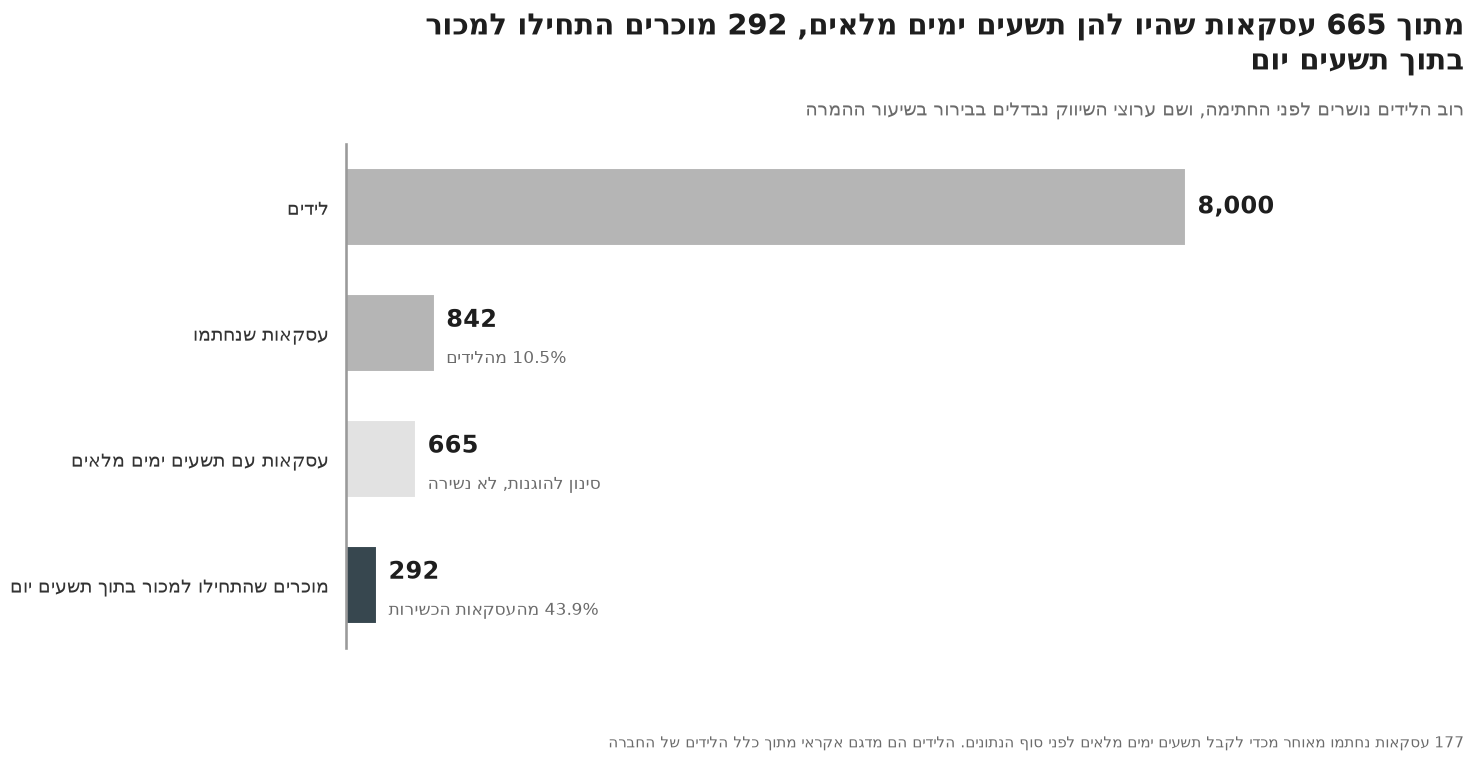

In [3]:
# 1. the funnel
n_deals, n_elig, n_act = len(deals), len(eligible), int(eligible.activated.sum())
f = pd.DataFrame({"stage": ["לידים", "עסקאות שנחתמו", "עסקאות עם תשעים ימים מלאים", "מוכרים שהתחילו למכור בתוך תשעים יום"],
                  "n": [LEADS_TOTAL, n_deals, n_elig, n_act],
                  "note": [None, "%.1f%% מהלידים" % (100*n_deals/LEADS_TOTAL), "סינון להוגנות, לא נשירה",
                           "%.1f%% מהעסקאות הכשירות" % (100*n_act/n_elig)]})
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.barplot(data=f, x="n", y="stage", hue="stage", palette=[C_GREY, C_GREY, C_LIGHT, C_ACCENT], legend=False, width=0.62, saturation=1, ax=ax)
for i, r in f.iterrows():
    ax.text(r.n + 110, i - (0.1 if pd.notna(r.note) else 0), "{:,}".format(r.n), va="center", fontsize=17, fontweight="bold", color=C_INK)
    if pd.notna(r.note):
        ax.text(r.n + 110, i + 0.2, r.note, va="center", fontsize=12.5, color=C_MUTED)
ax.set(xlabel="", ylabel="", xticks=[], xlim=(0, LEADS_TOTAL * 1.2)); ax.grid(False); sns.despine(ax=ax, bottom=True)
fig.subplots_adjust(top=0.80)
header(fig, "מתוך %d עסקאות שהיו להן תשעים ימים מלאים, %d מוכרים התחילו למכור בתוך תשעים יום" % (n_elig, n_act),
       "רוב הלידים נושרים לפני החתימה, ושם ערוצי השיווק נבדלים בבירור בשיעור ההמרה")
note(fig, "%d עסקאות נחתמו מאוחר מכדי לקבל תשעים ימים מלאים לפני סוף הנתונים. הלידים הם מדגם אקראי מתוך כלל הלידים של החברה"
     % (n_deals - n_elig))
save(fig, "01_funnel.png")

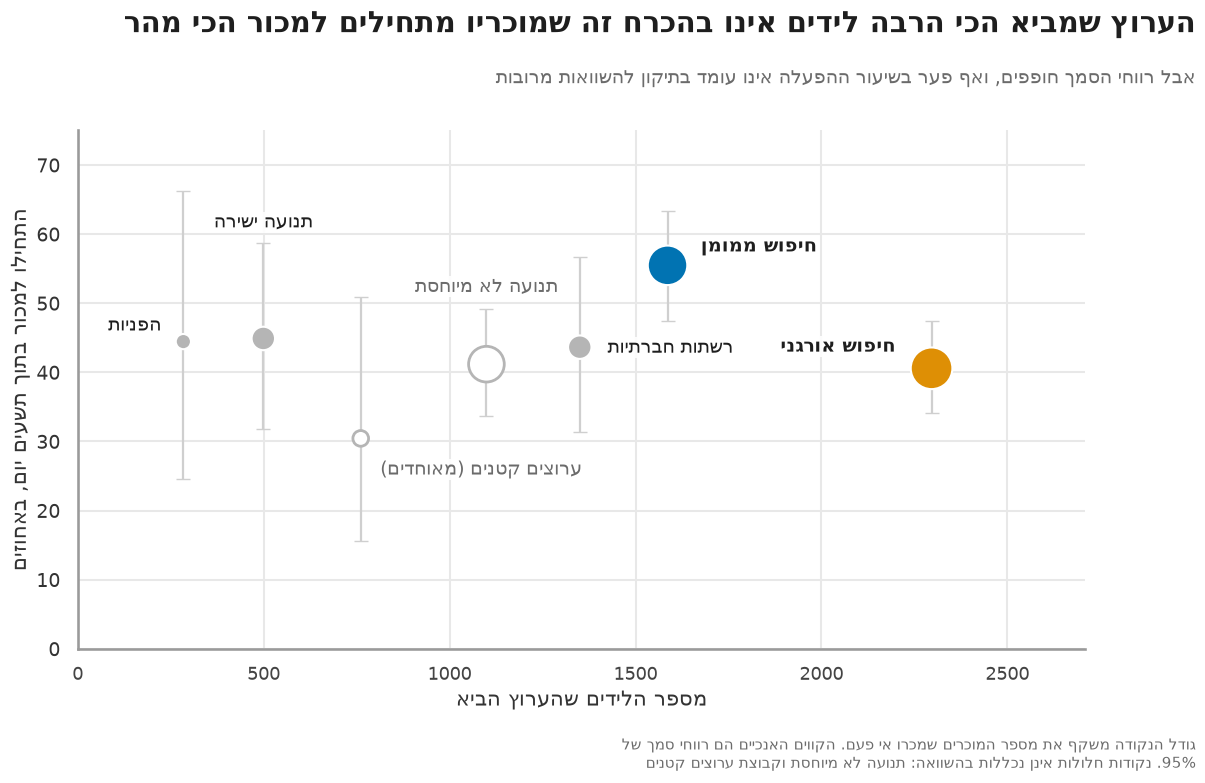

In [4]:
# 2. volume against 90-day activation
pts = CHANNELS + NON_CHANNELS
d = pd.DataFrame({"c": pts, "leads": [ch.loc[c, "leads"] for c in pts],
                  "rate": [100 * act.loc[c, "k"] / act.loc[c, "n"] for c in pts],
                  "sold": [ch.loc[c, "sellers_ever_sold"] for c in pts]})
d["ci"] = [wilson(*act.loc[c]) for c in pts]
d["group"] = d.c.map(lambda c: HE[c] if c in ("paid_search", "organic_search") else
                     "לא ערוץ שיווק" if c in NON_CHANNELS else "ערוץ אחר")
fig, ax = plt.subplots(figsize=FIGSIZE)
for _, r in d.iterrows():
    ax.errorbar(r.leads, r.rate, yerr=[[r.rate - 100*r.ci[0]], [100*r.ci[1] - r.rate]], fmt="none", ecolor="#CFCFCF", lw=1.6, capsize=5, zorder=1)
sns.scatterplot(data=d[d.group != "לא ערוץ שיווק"], x="leads", y="rate", size="sold", sizes=(120, 900), hue="group",
                palette={HE["paid_search"]: C_PAID, HE["organic_search"]: C_ORG, "ערוץ אחר": C_GREY},
                edgecolor="white", linewidth=1.5, legend=False, zorder=3, ax=ax)
nc = d[d.group == "לא ערוץ שיווק"]
ax.scatter(nc.leads, nc.rate, s=120 + 780 * (nc.sold - d.sold.min()) / (d.sold.max() - d.sold.min()),
           facecolor="white", edgecolor=C_GREY, linewidth=2, zorder=3)
POS = {"unknown": (0, 52, "center"), "social": (20, -4, "left"), "small_channels_merged": (14, -26, "left"),
       "referral": (-16, 8, "right"), "direct_traffic": (0, 80, "center"), "paid_search": (24, 10, "left"), "organic_search": (-26, 12, "right")}
for _, r in d.iterrows():
    dx, dy, ha = POS[r.c]
    ax.annotate(HE[r.c], (r.leads, r.rate), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=14,
                color=C_MUTED if r.c in NON_CHANNELS else C_INK, fontweight="bold" if r.c in ("paid_search", "organic_search") else "normal",
                zorder=4, bbox=dict(facecolor="white", edgecolor="none", pad=0.6, alpha=0.9))
ax.set(xlabel="מספר הלידים שהערוץ הביא", ylabel="התחילו למכור בתוך תשעים יום, באחוזים", ylim=(0, 75), xlim=(0, ch.leads.max() * 1.18))
fig.subplots_adjust(top=0.82)
header(fig, "הערוץ שמביא הכי הרבה לידים אינו בהכרח זה שמוכריו מתחילים למכור הכי מהר",
       "אבל רווחי הסמך חופפים, ואף פער בשיעור ההפעלה אינו עומד בתיקון להשוואות מרובות")
note(fig, "גודל הנקודה משקף את מספר המוכרים שמכרו אי פעם. הקווים האנכיים הם רווחי סמך של 95%. נקודות חלולות אינן נכללות בהשוואה: תנועה לא מיוחסת וקבוצת ערוצים קטנים")
save(fig, "02_volume_vs_activation.png")

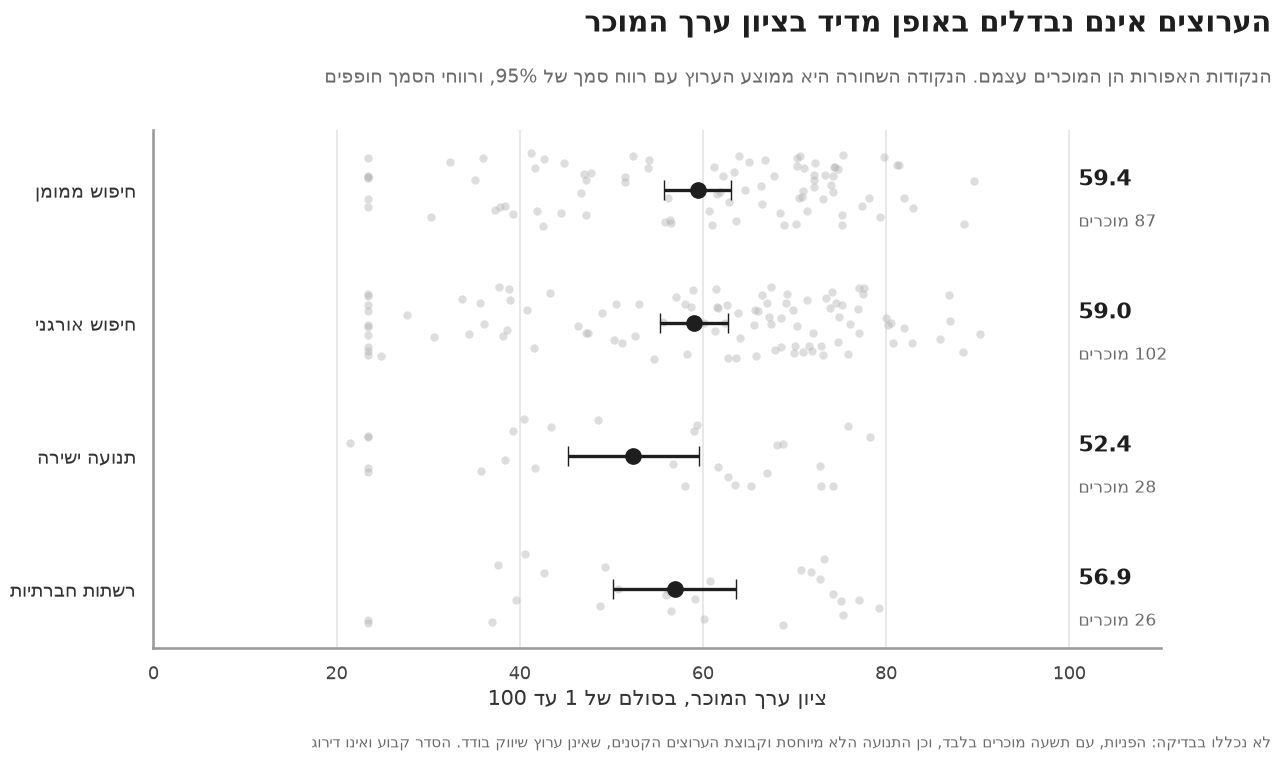

In [5]:
# 3. value score by channel: every seller, and the channel mean with its interval
s4 = sellers[sellers.channel.isin(TESTED)].assign(name=lambda x: x.channel.map(HE))
order = [HE[c] for c in TESTED]
fig, ax = plt.subplots(figsize=FIGSIZE)
np.random.seed(SEED)                     # seaborn jitters with the global generator; seed it so the chart reproduces
sns.stripplot(data=s4, x="value_score", y="name", order=order, color=C_GREY, alpha=0.45, size=6, jitter=0.28, ax=ax, zorder=1)
for i, c in enumerate(TESTED):
    r = ch.loc[c]
    ax.errorbar(r.score_mean, i, xerr=[[r.score_mean - r.score_ci_low], [r.score_ci_high - r.score_mean]],
                fmt="o", color=C_INK, ms=11, capsize=7, lw=2.4, zorder=3)
    ax.text(101, i - 0.08, "%.1f" % r.score_mean, va="center", fontsize=16, fontweight="bold", color=C_INK)
    ax.text(101, i + 0.24, "%d מוכרים" % r.sellers_scored, va="center", fontsize=12, color=C_MUTED)
ax.set(xlabel="ציון ערך המוכר, בסולם של 1 עד 100", ylabel="", xlim=(0, 110))
fig.subplots_adjust(top=0.82)
header(fig, "הערוצים אינם נבדלים באופן מדיד בציון ערך המוכר",
       "הנקודות האפורות הן המוכרים עצמם. הנקודה השחורה היא ממוצע הערוץ עם רווח סמך של 95%, ורווחי הסמך חופפים")
note(fig, "לא נכללו בבדיקה: הפניות, עם תשעה מוכרים בלבד, וכן התנועה הלא מיוחסת וקבוצת הערוצים הקטנים, שאינן ערוץ שיווק בודד. "
          "הסדר קבוע ואינו דירוג")
save(fig, "03_value_by_channel.png")

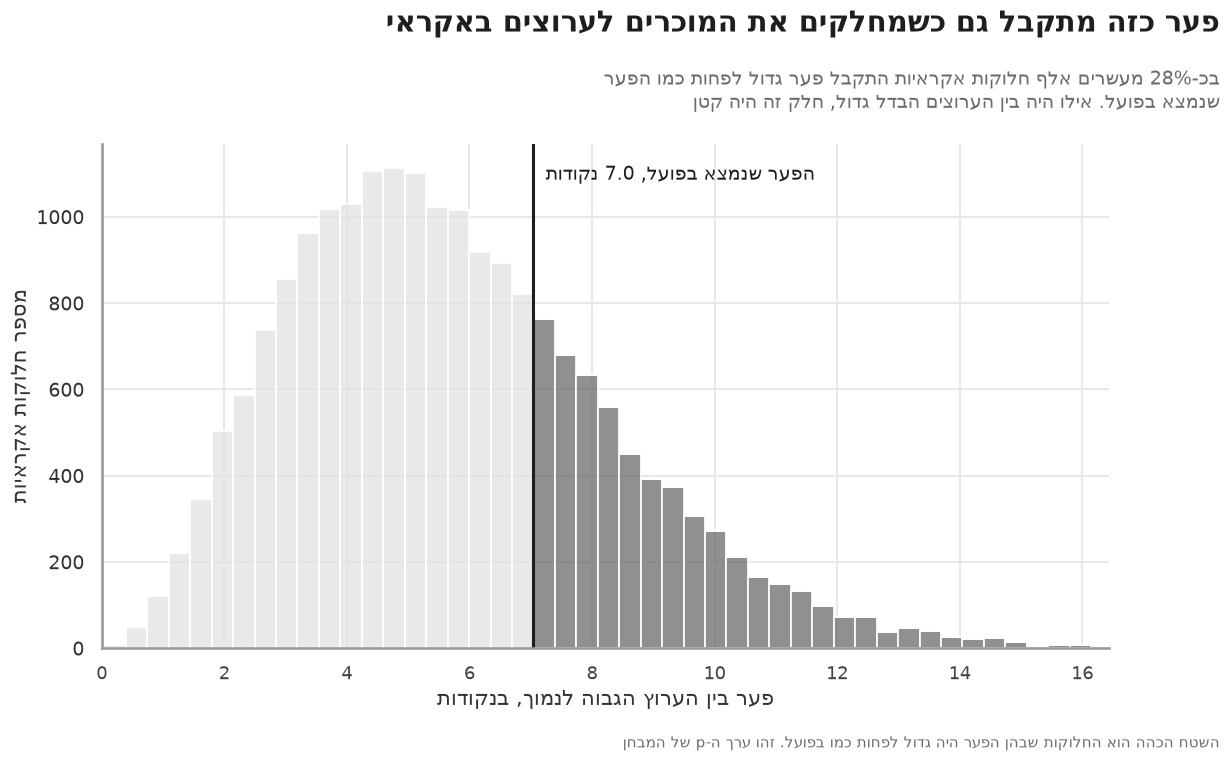

In [6]:
# 4. the permutation test as a lottery
nd = pd.DataFrame({"gap": null, "side": np.where(null >= gap, "גדול לפחות כמו בפועל", "קטן יותר")})
fig, ax = plt.subplots(figsize=FIGSIZE)
w_ = 0.35; bins = gap + w_ * np.arange(-int(gap / w_) - 1, int((null.max() - gap) / w_) + 2)
sns.histplot(data=nd, x="gap", hue="side", bins=bins, palette={"קטן יותר": C_LIGHT, "גדול לפחות כמו בפועל": C_MUTED},
             multiple="stack", edgecolor="white", legend=False, ax=ax)
ax.axvline(gap, color=C_INK, lw=2.2)
ax.text(gap + 0.2, ax.get_ylim()[1] * 0.93, "הפער שנמצא בפועל, %.1f נקודות" % gap, fontsize=14, color=C_INK)
ax.set(xlabel="פער בין הערוץ הגבוה לנמוך, בנקודות", ylabel="מספר חלוקות אקראיות", xlim=(0, np.percentile(null, 99.9) + 0.5))
fig.subplots_adjust(top=0.80)
header(fig, "פער כזה מתקבל גם כשמחלקים את המוכרים לערוצים באקראי",
       "בכ-%.0f%% מעשרים אלף חלוקות אקראיות התקבל פער גדול לפחות כמו הפער שנמצא בפועל. אילו היה בין הערוצים הבדל גדול, "
       "חלק זה היה קטן" % (100 * p_value))
note(fig, "השטח הכהה הוא החלוקות שבהן הפער היה גדול לפחות כמו בפועל. זהו ערך ה-p של המבחן")
save(fig, "04_permutation.png")

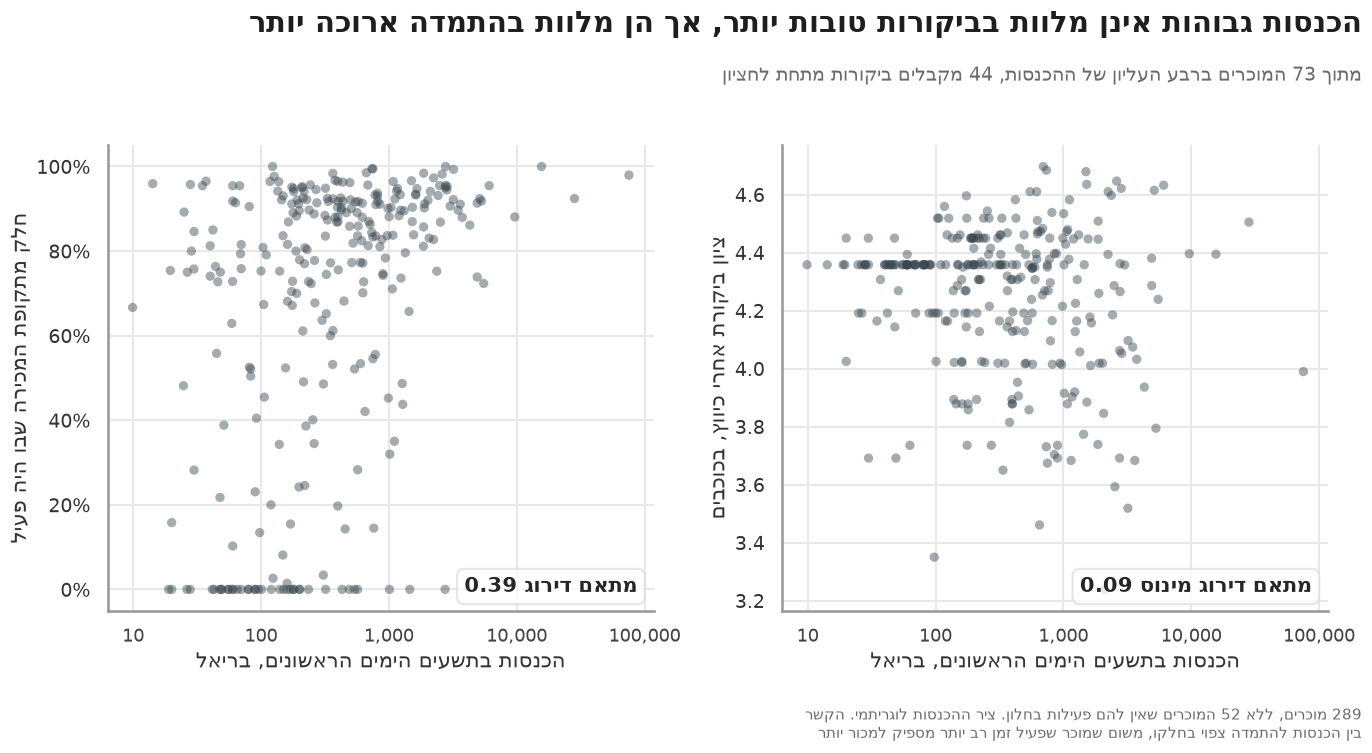

In [7]:
# 5. sub-question 2: revenue against satisfaction and against staying power
top = v.revenue_window >= v.revenue_window.quantile(0.75)
below = int((top & (v.review_shrunk < v.review_shrunk.median())).sum())
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True)
for ax, col, lab, rho in [(axes[1], "review_shrunk", "ציון ביקורת אחרי כיווץ, בכוכבים", rho_sat),
                          (axes[0], "tenure_ratio", "חלק מתקופת המכירה שבו היה פעיל", rho_ten)]:
    sns.scatterplot(data=v, x="revenue_window", y=col, color=C_ACCENT, alpha=0.45, s=45, edgecolor="none", ax=ax)
    ax.set_xscale("log"); ax.set(xlabel="הכנסות בתשעים הימים הראשונים, בריאל", ylabel=lab)
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: "{:,.0f}".format(x)))
    rho_txt = ("מינוס %.2f" % -rho) if rho < 0 else ("%.2f" % rho)
    ax.text(0.97, 0.04, "מתאם דירוג %s" % rho_txt, transform=ax.transAxes, ha="right", fontsize=15, fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="#DDDDDD", boxstyle="round,pad=0.35", alpha=0.75))
axes[0].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
fig.tight_layout(rect=(0, 0, 1, 0.83))
header(fig, "הכנסות גבוהות אינן מלוות בביקורות טובות יותר, אך הן מלוות בהתמדה ארוכה יותר",
       "מתוך %d המוכרים ברבע העליון של ההכנסות, %d מקבלים ביקורות מתחת לחציון" % (int(top.sum()), below), width=90)
note(fig, "%d מוכרים, ללא %d המוכרים שאין להם פעילות בחלון. ציר ההכנסות לוגריתמי. הקשר בין הכנסות להתמדה צפוי בחלקו, "
          "משום שמוכר שפעיל זמן רב יותר מספיק למכור יותר" % (len(v), n_none))
save(fig, "05_revenue_vs_value.png")

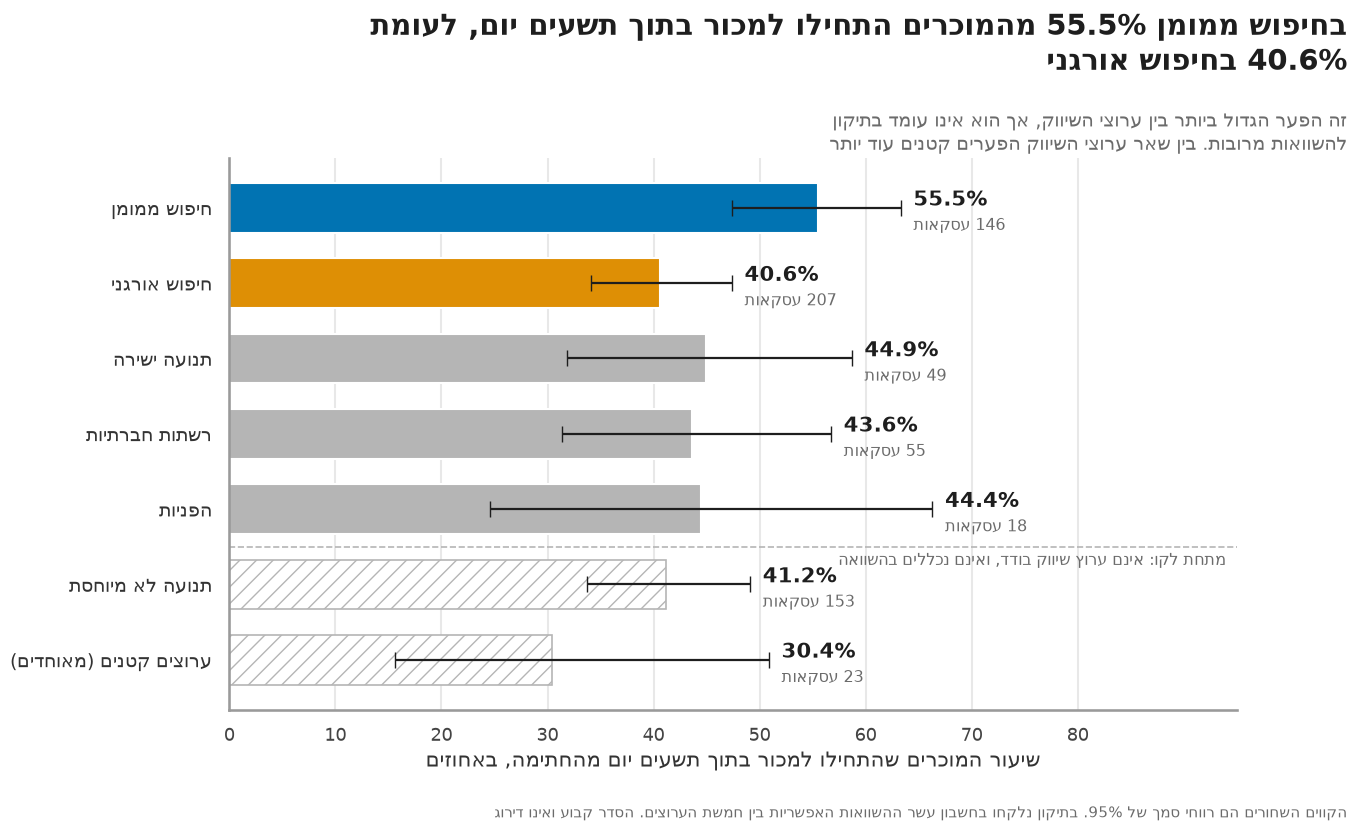

In [8]:
# 6. the key chart: 90-day activation by channel
rows = CHANNELS + NON_CHANNELS
a = pd.DataFrame({"name": [HE[c] for c in rows], "rate": [100 * act.loc[c, "k"] / act.loc[c, "n"] for c in rows],
                  "n": [act.loc[c, "n"] for c in rows], "ci": [wilson(*act.loc[c]) for c in rows]})
cols = [C_PAID, C_ORG, C_GREY, C_GREY, C_GREY, "white", "white"]
fig, ax = plt.subplots(figsize=(13, 8))
sns.barplot(data=a, x="rate", y="name", hue="name", palette=cols, legend=False, width=0.66, saturation=1, ax=ax)
for bar, c in zip(ax.patches, rows):
    if c in NON_CHANNELS:
        bar.set_hatch("//"); bar.set_edgecolor(C_GREY); bar.set_linewidth(1.2)
for i, r in a.iterrows():
    ax.errorbar(r.rate, i, xerr=[[r.rate - 100*r.ci[0]], [100*r.ci[1] - r.rate]], fmt="none", ecolor=C_INK, lw=1.6, capsize=6)
    ax.text(100*r.ci[1] + 1.2, i - 0.1, "%.1f%%" % r.rate, va="center", fontsize=15, fontweight="bold", color=C_INK)
    ax.text(100*r.ci[1] + 1.2, i + 0.24, "%d עסקאות" % r.n, va="center", fontsize=11.5, color=C_MUTED)
ax.axhline(len(CHANNELS) - 0.5, color=C_GREY, ls="--", lw=1.2)
ax.text(94, len(CHANNELS) - 0.42, "מתחת לקו: אינם ערוץ שיווק בודד, ואינם נכללים בהשוואה", ha="right", va="top", fontsize=11.5, color=C_MUTED)
ax.set(xlabel="שיעור המוכרים שהתחילו למכור בתוך תשעים יום מהחתימה, באחוזים", ylabel="", xlim=(0, 95), xticks=range(0, 81, 10))
fig.subplots_adjust(top=0.80)
header(fig, "בחיפוש ממומן %.1f%% מהמוכרים התחילו למכור בתוך תשעים יום, לעומת %.1f%% בחיפוש אורגני"
       % (a.rate[0], a.rate[1]),
       "זה הפער הגדול ביותר בין ערוצי השיווק, אך הוא אינו עומד בתיקון להשוואות מרובות. בין שאר ערוצי השיווק הפערים קטנים עוד יותר", width=62)
note(fig, "הקווים השחורים הם רווחי סמך של 95%. בתיקון נלקחו בחשבון עשר ההשוואות האפשריות בין חמשת הערוצים. "
          "הסדר קבוע ואינו דירוג")
save(fig, "06_activation_by_channel.png")

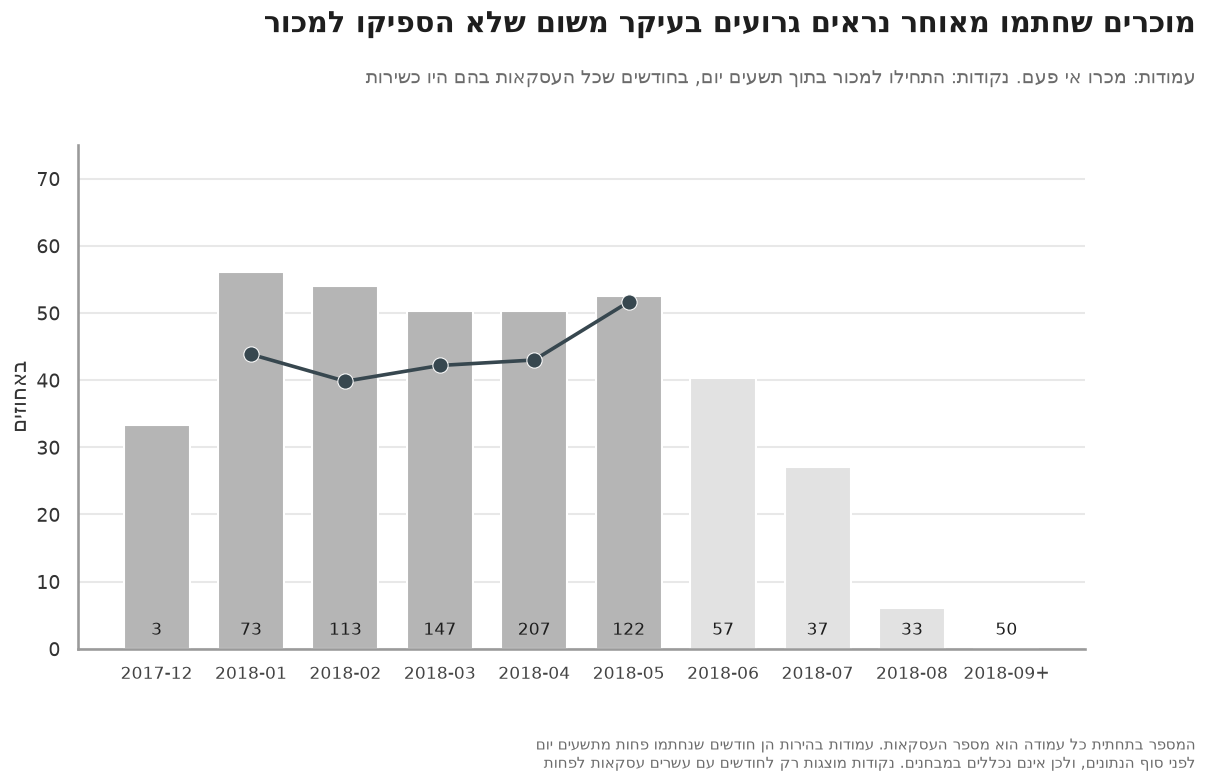

In [9]:
# 7. why a 90-day window: activation by signing month
dm = deals.assign(month=deals.won_day.dt.to_period("M"))
dm["bucket"] = dm.month.astype(str).where(dm.month < pd.Period("2018-09", "M"), "2018-09+")
g = dm.groupby("bucket").agg(n=("mql_id", "size"), ever=("first_sale_date", lambda s: 100 * s.notna().mean()))
g = g.join(dm[dm.eligible].groupby("bucket").agg(n_elig=("mql_id", "size"), act90=("activated", lambda s: 100 * s.mean())))
g = g.reset_index()
full = g.act90.notna() & (g.n >= 20) & (g.n_elig == g.n)       # months with 20+ deals, every one with a full window
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.barplot(data=g, x="bucket", y="ever", hue="bucket", palette=[C_GREY if f else C_LIGHT for f in (g.n_elig == g.n)],
            legend=False, width=0.7, ax=ax)
for i, r in g.iterrows():
    ax.text(i, 1.5, "%d" % r.n, ha="center", va="bottom", fontsize=12, color=C_INK)
sns.lineplot(x=g.index[full], y=g.act90[full], color=C_ACCENT, marker="o", markersize=11, lw=2.6, ax=ax)
ax.set(xlabel="", ylabel="באחוזים", ylim=(0, 75)); ax.tick_params(axis="x", labelsize=12)
fig.subplots_adjust(top=0.80)
header(fig, "מוכרים שחתמו מאוחר נראים גרועים בעיקר משום שלא הספיקו למכור",
       "עמודות: מכרו אי פעם. נקודות: התחילו למכור בתוך תשעים יום, בחודשים שכל העסקאות בהם היו כשירות")
note(fig, "המספר בתחתית כל עמודה הוא מספר העסקאות. עמודות בהירות הן חודשים שנחתמו פחות מתשעים יום לפני סוף הנתונים, "
          "ולכן אינם נכללים במבחנים. נקודות מוצגות רק לחודשים עם עשרים עסקאות לפחות")
save(fig, "07_activation_by_month.png")

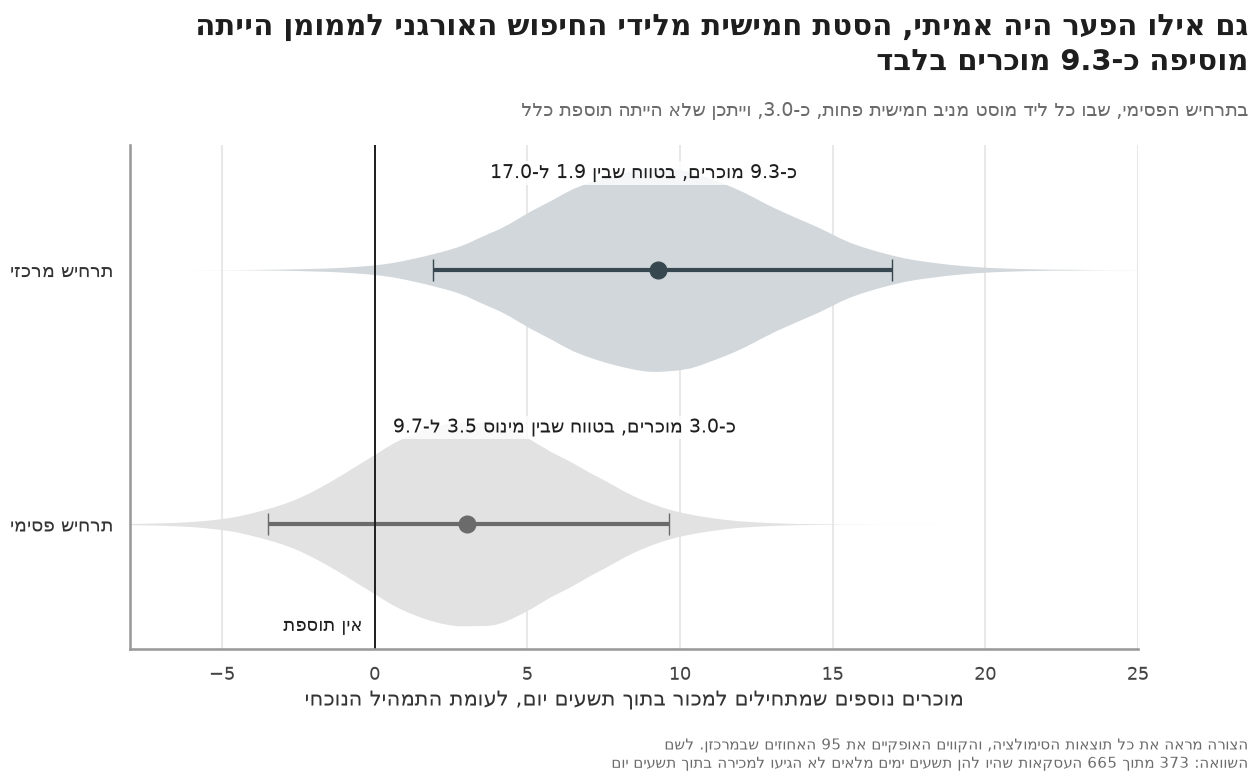

In [10]:
# 8. the simulation: the whole spread of outcomes, not only the range
lab_c, lab_p = "תרחיש מרכזי", "תרחיש פסימי"
sd = pd.concat([pd.DataFrame({"gain": gain, "s": lab_c}), pd.DataFrame({"gain": pess, "s": lab_p})])
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.violinplot(data=sd, x="gain", y="s", hue="s", palette={lab_c: "#CFD8DC", lab_p: C_LIGHT}, inner=None, cut=0,
               linewidth=0, legend=False, density_norm="width", ax=ax)
for i, (g_, col) in enumerate([(gain, C_ACCENT), (pess, C_MUTED)]):
    med, lo, hi = np.median(g_), np.percentile(g_, 2.5), np.percentile(g_, 97.5)
    ax.errorbar(med, i, xerr=[[med - lo], [hi - med]], fmt="o", color=col, ms=12, capsize=8, lw=3)
    lo_txt = ("מינוס %.1f" % -lo) if lo < 0 else ("%.1f" % lo)
    ax.text(max(med - 5.5, 0.6), i - 0.36, "כ-%.1f מוכרים, בטווח שבין %s ל-%.1f" % (med, lo_txt, hi), ha="left", fontsize=14, color=C_INK,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5))
ax.axvline(0, color=C_INK, lw=1.4)
ax.text(-0.4, 1.42, "אין תוספת", ha="right", fontsize=13, color=C_INK)
ax.set(xlabel="מוכרים נוספים שמתחילים למכור בתוך תשעים יום, לעומת התמהיל הנוכחי", ylabel="", xlim=(-8, 25))
fig.subplots_adjust(top=0.80)
header(fig, "גם אילו הפער היה אמיתי, הסטת חמישית מלידי החיפוש האורגני לממומן הייתה מוסיפה כ-%.1f מוכרים בלבד" % np.median(gain),
       "בתרחיש הפסימי, שבו כל ליד מוסט מניב חמישית פחות, כ-%.1f, וייתכן שלא הייתה תוספת כלל" % np.median(pess))
note(fig, "הצורה מראה את כל תוצאות הסימולציה, והקווים האופקיים את 95 האחוזים שבמרכזן. לשם השוואה: %d מתוך %d העסקאות "
          "שהיו להן תשעים ימים מלאים לא הגיעו למכירה בתוך תשעים יום" % (n_elig - n_act, n_elig))
save(fig, "08_simulation.png")

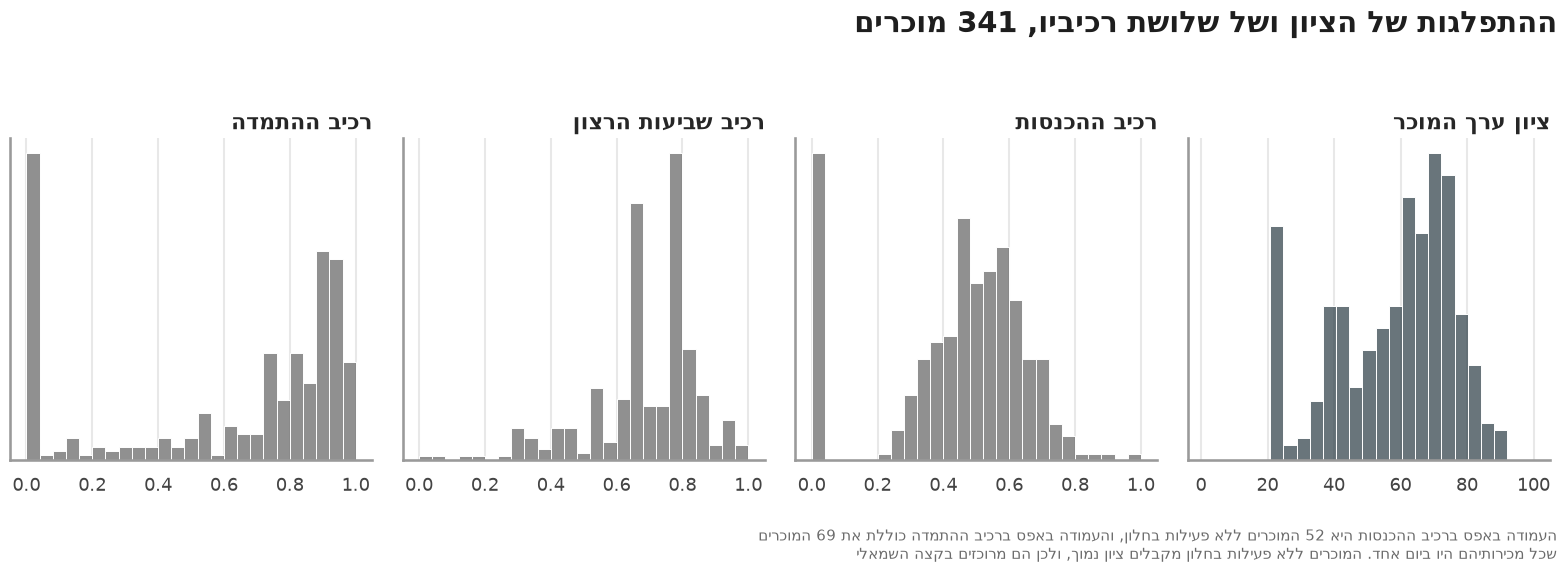

In [11]:
# 9. the score and its three components
names = {"value_score": "ציון ערך המוכר", "revenue_component": "רכיב ההכנסות",
         "satisfaction_component": "רכיב שביעות הרצון", "tenure_component": "רכיב ההתמדה"}
fig, axes = plt.subplots(1, 4, figsize=(16, 5.2))
for ax, (c, rng_) in zip(axes[::-1], [("value_score", (1, 100)), ("revenue_component", (0, 1)),
                                      ("satisfaction_component", (0, 1)), ("tenure_component", (0, 1))]):
    sns.histplot(sellers[c], bins=25, binrange=rng_, color=C_ACCENT if c == "value_score" else C_MUTED,
                 edgecolor="white", ax=ax)
    ax.set(title="", xlabel="", ylabel="", yticks=[])
    ax.set_title(names[c], loc="right", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.84))
header(fig, "ההתפלגות של הציון ושל שלושת רכיביו, %d מוכרים" % len(sellers))
note(fig, "העמודה באפס ברכיב ההכנסות היא %d המוכרים ללא פעילות בחלון, והעמודה באפס ברכיב ההתמדה כוללת את %d המוכרים "
          "שכל מכירותיהם היו ביום אחד. המוכרים ללא פעילות בחלון מקבלים ציון נמוך, ולכן הם מרוכזים בקצה השמאלי"
     % (n_none, int((sellers.active_span_days == 0).sum())))
save(fig, "09_distributions.png")

In [12]:
print("written to charts/:", sorted(p.name for p in OUT.glob("*.png")))

written to charts/: ['01_funnel.png', '02_volume_vs_activation.png', '03_value_by_channel.png', '04_permutation.png', '05_revenue_vs_value.png', '06_activation_by_channel.png', '07_activation_by_month.png', '08_simulation.png', '09_distributions.png']
